# 07 · Nelson–Siegel 曲线动态（idea E）

复现 Bianchi, Fan, Miffre & Zhang (2023, JBF 154)：每天用最近 4 张合约的**价格水平**拟合 Nelson–Siegel 曲线，按 **slope beta 的一日变化 ΔβS** 的符号做 1st/4th slope spread，持有一天。协议见 D-016，λ 超参数和资本口径见 D-017。

- 拟合：$F_t(M)=\beta_L+\beta_S\,s(\lambda M)+\beta_C\,c(\lambda M)$，$s(x)=(1-e^{-x})/x$，$c(x)=s(x)-e^{-x}$，M 是到最后交易日的月数。
- λ 是**超参数**：几种因果规则在 validation（2006–2015）上比较，按**可交易**的 gross Sharpe 选一个，test（2016–2026）只看一次。
- 时点：论文在信号的同一个 settle 成交（不可交易）；我们的主结果是 t 出信号、t+1 成交。两者都报。
- 资本：\$1m 整个组合（以前 notebook 06 用 \$10m）；另看 \$100k–\$10m 和整手取整。
- 所有诊断都是时序的，每个商品只和自己的历史比。

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

In [2]:
import numpy as np
import pandas as pd
from IPython.display import display

from src import costs, horizon, marks, nelson_siegel as ns, panel, report, simulate, sizing, specs
from src import figures as F
from src import plotstyle as ps

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 24)
print("LaTeX text rendering:", ps.use())

STRATEGY = "NS slope (idea E)"
VALID = ("2006-01-01", "2015-12-31")
TEST_START = "2016-01-01"
PAPER_SAMPLE = ("1992-01-02", "2019-06-28")
CFG = simulate.SimConfig(capital=1e6)

LaTeX text rendering: True


## 1. 数据：哪些天能凑满 4 张合约

Eligible = 有 settle、不在交割月、不晚于最后交易日。我们只有 M1–M4，所以 M1 进入交割月（谷物、金属、软商品每月约半个月）的日子只剩 3 张 → snapshot OLS 跳过、显式平仓（D-016 item 2）。

最后交易日：已到期合约取其在 M1–M4 滚动中最后出现的日子；样本末尾未到期的按品种历史中位偏移推。下表是每个商品能拟合的天数占比。

In [3]:
rank = pd.read_parquet("data/processed/rank.parquet")
contract = panel.build_backtest_panel(rank, d=5, k=5)["contract"]
mk = marks.build_marks(contract, specs.load_contract_specs())
curve = ns.eligible_curve(contract)
display(ns.coverage(curve).round(3).T)

root,FC,GC,LC,SI,HG,SM,BO,LH,S,RR,LB,KC,O,W,C,CC,JO,CT,CO,NG,CL,HO,XB,SB
days,10283.000,10253.000,10284.000,10252.00,9513.000,10277.000,10277.000,10223.00,10276.00,9494.00,9350.000,10230.000,10276.00,10277.000,10276.000,10230.000,10256.000,10255.000,9788.000,9181.000,10250.000,10126.000,5296.000,10230.000
days_4,4235.000,5587.000,5645.000,6356.00,5905.000,6598.000,6600.000,6750.00,7087.00,6745.00,6870.000,7550.000,7806.00,7993.000,7993.000,8147.000,8268.000,9138.000,9073.000,8738.000,9759.000,9642.000,5046.000,10061.000
share_4,0.412,0.545,0.549,0.62,0.621,0.642,0.642,0.66,0.69,0.71,0.735,0.738,0.76,0.778,0.778,0.796,0.806,0.891,0.927,0.952,0.952,0.952,0.953,0.983


## 2. 拟合（论文的 λ 规则）

论文的 λ：$\lambda_t = 1.7933/\bar M_t$（curvature 载荷在平均期限处最大，论文脚注 4）。下表对应论文 Table 3：β 的均值、Δβ 的一阶自相关、λ、平均 R²（完整模型、去掉 curvature 的 L+S、去掉 slope 的 L+C）。论文：96.5%、82.7%、37.5%。

注意：只有 M1–M4，换月那天旧近月到期（期限为 0）不计入，当天凑不满 4 张，所以 **Δβ 永远不会跨 roll 计算**（D-016 item 5 的 robustness 自动成立）。

In [4]:
base = ns.build_slope_strategy(contract, mk, rule="paper")
display(ns.fit_summary(base["fits"], base["sig"]).round(3))

,bL_mean,bS_mean,bS_sd,bC_mean,ac1_dbS,ac1_dbC,lam_mean,r2,r2_ls,r2_lc
root,,,,,,,,,,
BO,33.587,-0.267,4.038,0.393,0.014,-0.162,0.560,98.448,89.327,42.875
C,372.830,-22.312,82.290,2.916,0.089,0.125,0.362,96.577,82.559,45.201
CC,2240.155,34.057,793.644,34.081,-0.065,-0.107,0.363,98.289,84.419,45.638
CL,48.210,0.548,5.432,1.130,0.086,-0.061,0.914,99.316,88.324,44.948
CO,53.179,0.990,5.139,0.846,0.033,-0.155,0.918,98.712,89.309,44.043
CT,68.701,1.246,21.013,3.810,0.068,0.004,0.372,95.069,74.850,43.937
FC,128.376,-2.422,15.888,-7.517,-0.006,-0.094,0.526,94.993,73.035,39.210
GC,1035.777,-41.041,55.852,-41.922,-0.046,-0.225,0.407,99.855,95.850,37.302
HG,230.630,1.913,20.088,5.377,0.050,-0.033,0.346,99.344,88.010,43.906


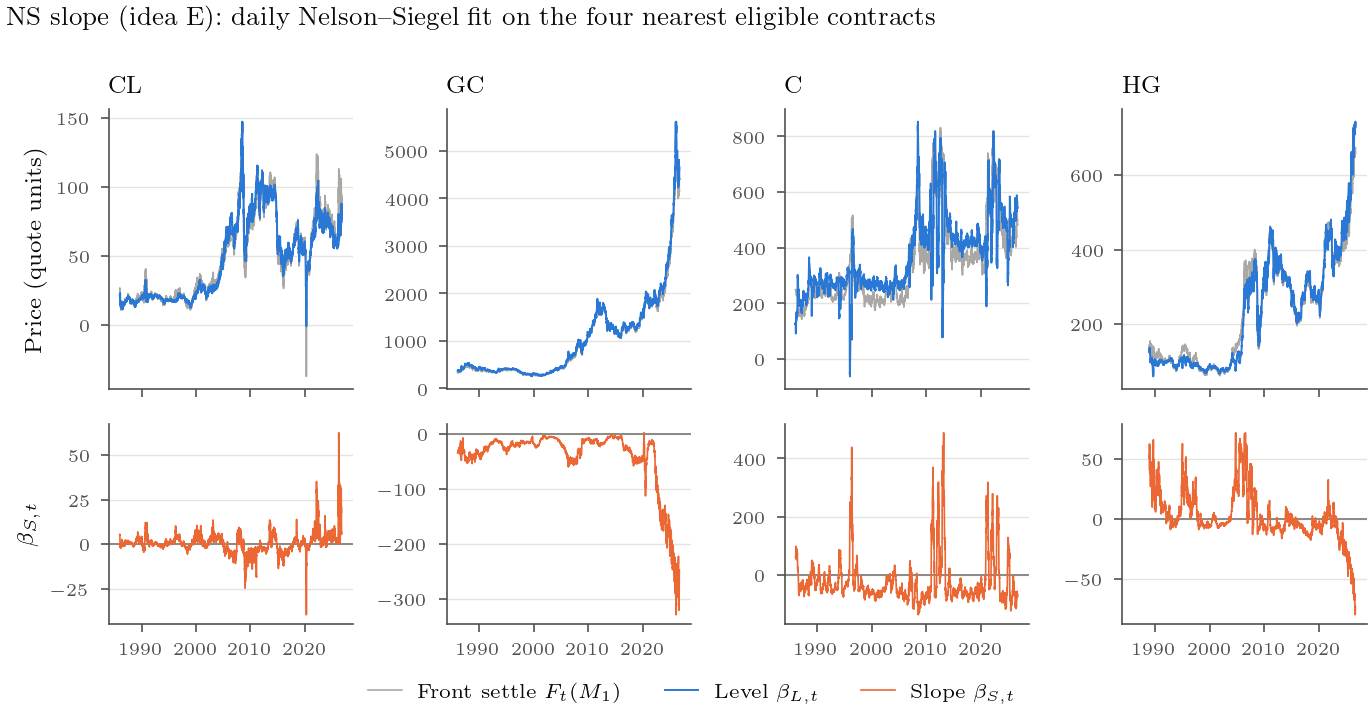

In [5]:
fig = F.ns_betas(base["fits"], base["wide"], ["CL", "GC", "C", "HG"], STRATEGY)
ps.save(fig, "ns_betas");

### 2b. 拟合显著性：每个成分真的有用吗

每个商品每天得到一个 R²；按 21 天块对日期做 moving-block bootstrap（2000 次），看平均 R² 的分布。然后做**配对** bootstrap：同一天里比较嵌套模型，看加一项之后拟合是否显著变好。

- **样本内 R² 不能直接比**：嵌套 OLS 多一个回归项，R² 只会变大，"ΔR² > 0" 是必然的。所以主口径用**调整 R²**（n = 4：L+S 的惩罚 3/2，L+S+C 是 3/1；只有 level 时调整 R² = 0）。
- **样本外口径**：留一张合约出来，用另外三张拟合后预测它（leave-one-out），R²_LOO = 1 − PRESS/SST。这直接回答"能不能更好地描述曲线形状"。LOO 尾部很重（三张合约精确拟合后外推到两端会爆），所以用**中位数**做 bootstrap。
- 两个台阶：**L → L+S**（加 slope），**L+S → L+S+C**（加 curvature）。

In [6]:
quality = ns.fit_quality(base["wide"], ns.lambda_series(base["wide"], "paper"))
quality = quality.assign(
    gain_slope=quality["adj_LS"] - quality["adj_L"], gain_curv=quality["adj_LSC"] - quality["adj_LS"],
    loo_gain_slope=quality["loo_LS"] - quality["loo_L"], loo_gain_curv=quality["loo_LSC"] - quality["loo_LS"])
cols = [f"{m}_{k}" for m in ("r2", "adj", "loo") for k in ns.MODELS]
display(pd.DataFrame({"mean": quality[cols].mean(), "median": quality[cols].median()}).T.round(3))

boot_r2, draws_r2 = horizon.block_bootstrap_mean(quality, "r2_LSC", block=21, n_boot=2000)
fit_tests = {name: horizon.block_bootstrap_mean(quality, col, block=21, n_boot=2000, stat=stat)
             for name, col, stat in [("adj: + slope", "gain_slope", "mean"), ("adj: + curvature", "gain_curv", "mean"),
                                     ("LOO: + slope", "loo_gain_slope", "median"), ("LOO: + curvature", "loo_gain_curv", "median")]}
display(pd.DataFrame({name: {"better (p<0.05)": int(((s["p_value"] < 0.05) & (s["mean"] > 0)).sum()),
                             "worse (p<0.05)": int(((s["p_value"] < 0.05) & (s["mean"] < 0)).sum()),
                             "median gain": s["mean"].median()} for name, (s, _d) in fit_tests.items()}).round(3))

,r2_L,r2_LS,r2_LC,r2_LSC,adj_L,adj_LS,adj_LC,adj_LSC,loo_L,loo_LS,loo_LC,loo_LSC
mean,0.0,0.815,0.433,0.966,0.0,0.722,0.150,0.898,-0.778,-0.466,-10.143,-3.569
median,0.0,0.944,0.419,0.997,0.0,0.916,0.129,0.992,-0.778,0.579,-8.385,0.704


,adj: + slope,adj: + curvature,LOO: + slope,LOO: + curvature
better (p<0.05),24.000,24.000,22.000,11.00
worse (p<0.05),0.000,0.000,0.000,9.00
median gain,0.723,0.172,1.375,0.01


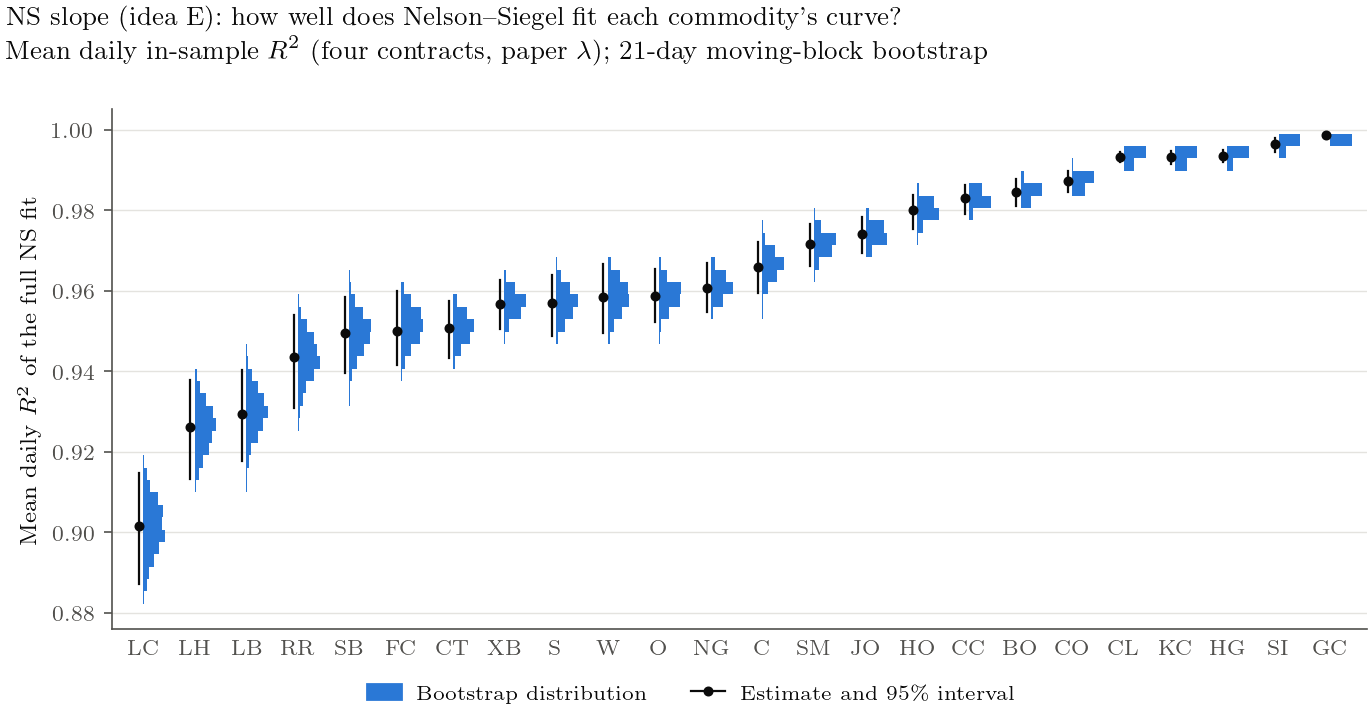

In [7]:
fig = F.bootstrap_distribution(
    boot_r2, draws_r2, "mean", r"Mean daily $R^2$ of the full NS fit",
    ps.tex(f"{STRATEGY}: how well does Nelson--Siegel fit each commodity's curve?" + "\n"
           + r"Mean daily in-sample $R^2$ (four contracts, paper $\lambda$); 21-day moving-block bootstrap"),
    test=False)
ps.save(fig, "ns_r2_bootstrap");

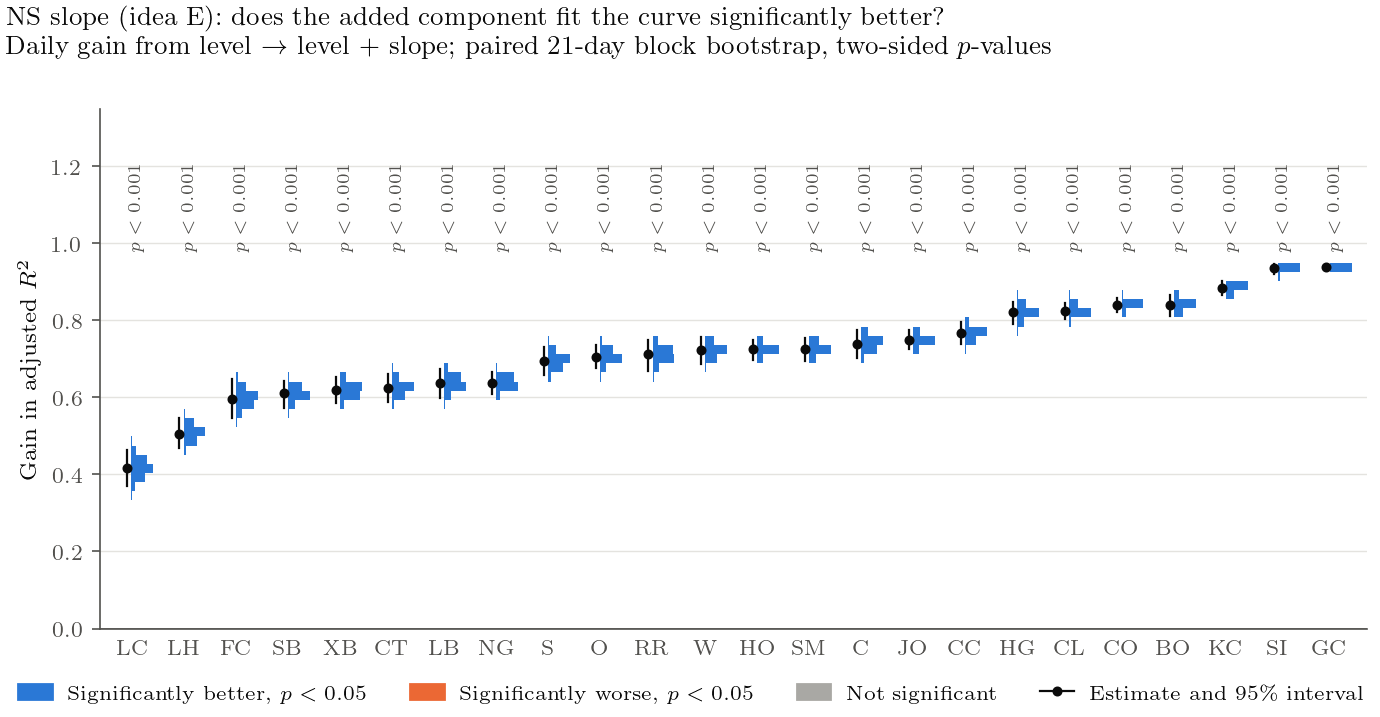

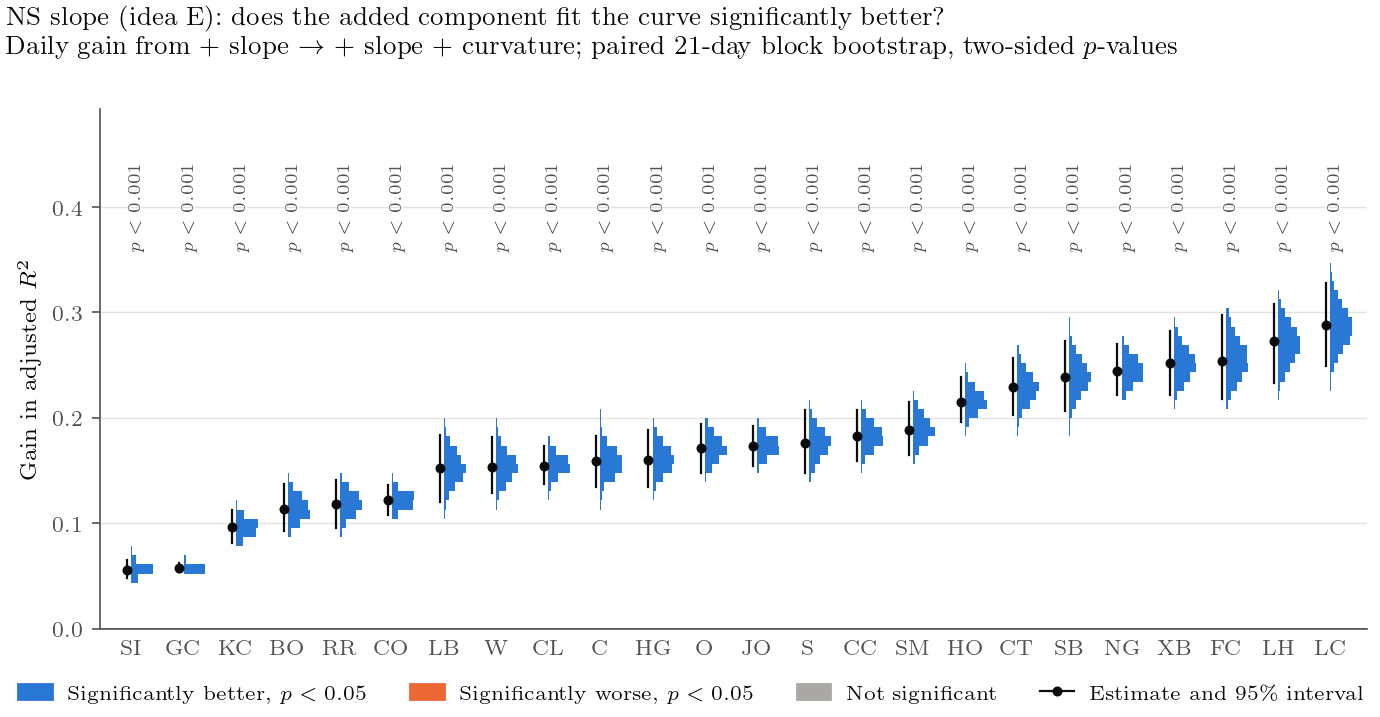

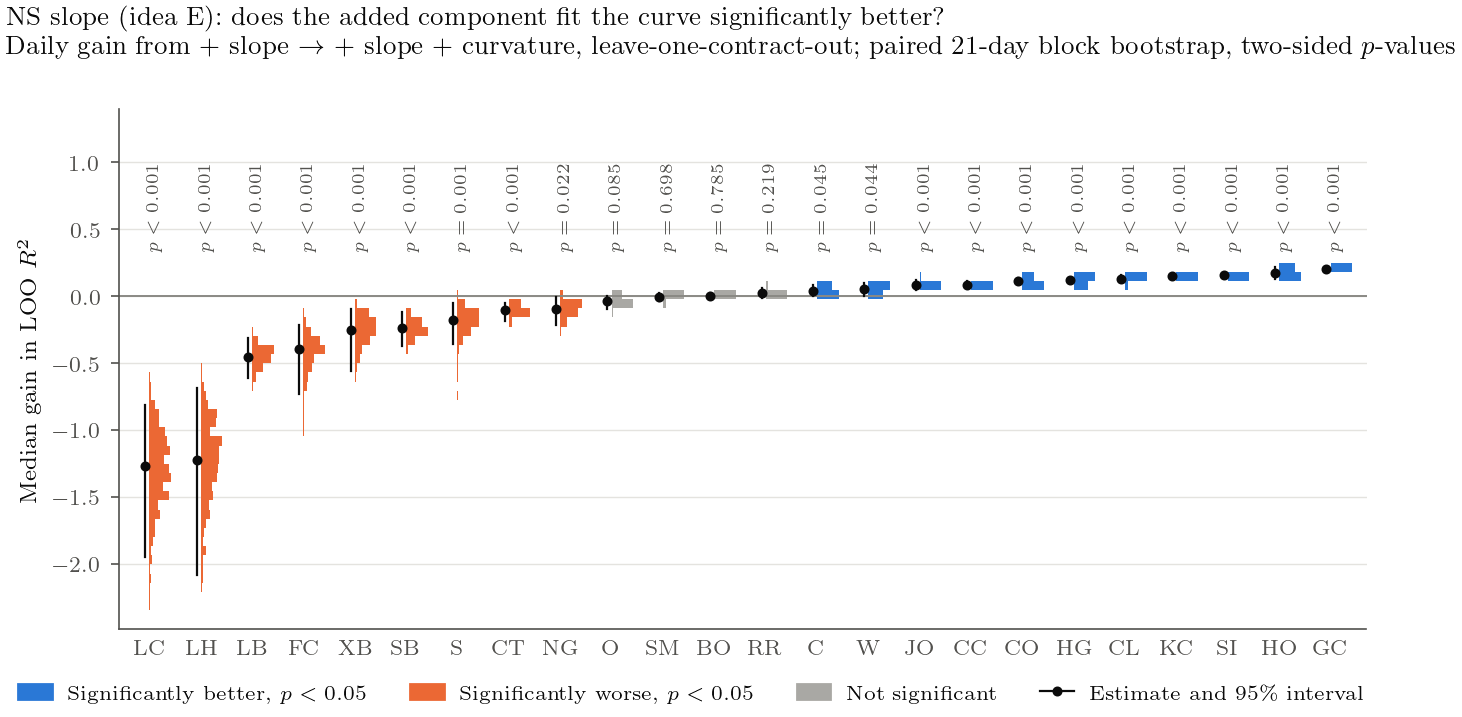

In [8]:
gain_figs = [
    ("adj: + slope", r"Gain in adjusted $R^2$", "level $\\to$ level + slope", "ns_gain_slope_adj"),
    ("adj: + curvature", r"Gain in adjusted $R^2$", "+ slope $\\to$ + slope + curvature", "ns_gain_curv_adj"),
    ("LOO: + curvature", r"Median gain in LOO $R^2$", "+ slope $\\to$ + slope + curvature, leave-one-contract-out", "ns_gain_curv_loo"),
]
for name, ylabel, step, fname in gain_figs:
    s, d = fit_tests[name]
    title = ps.tex(f"{STRATEGY}: does the added component fit the curve significantly better?" + "\n"
                   + f"Daily gain from {step}; paired 21-day block bootstrap, two-sided $p$-values")
    fig = F.bootstrap_distribution(s, d, "mean", ylabel, title, signed=True)
    ps.save(fig, fname)

## 3. λ 超参数：在 validation 上选

候选（都是因果的，只用 t 及以前的信息）：

- `paper`：$1.7933/\bar M_t$；
- `fixed_m`：固定 λ，curvature 峰值在 m 个月（m = 2, 4, 6）；
- `rolling_ssr`：每个品种在过去 252 个拟合日上残差平方和最小的 λ（网格 0.05–2，t 当天不用）。

选择标准：validation 期（2006–2015）**可交易**回测的 gross Sharpe（t+1 成交、日频、等权、\$1m）。同时报论文时点的 Sharpe 作对照。

In [9]:
valid_rows, strategies = [], {}
for rule in ns.LAMBDA_RULES:
    st = ns.build_slope_strategy(contract, mk, rule=rule)
    res_r = simulate.simulate(sizing.legs_from_signal(st["signal"], st["pairs"]), mk, CFG)
    fwd_r = horizon.forward_returns(st["pairs"], mk, horizons=[(0, 1), (1, 2)])
    paper_r = report.return_summary(report.execution_free_returns(fwd_r, st["signal"], "fwd_0_1"), *VALID)
    trad = report.performance_table(res_r, *VALID).set_index("layer").loc["gross"]
    valid_rows.append(dict(rule=rule, sharpe_tradable=trad["sharpe"], t_tradable=trad["t_nw"],
                           sharpe_paper=paper_r["sharpe"], t_paper=paper_r["t_nw"],
                           lam_median=st["fits"]["lam"].median()))
    strategies[rule] = dict(st=st, res=res_r, fwd=fwd_r)
lam_table = pd.DataFrame(valid_rows)
CHOSEN = lam_table.loc[lam_table["sharpe_tradable"].idxmax(), "rule"]
print("chosen lambda rule:", CHOSEN)
display(lam_table.round(3))

chosen lambda rule: rolling_ssr


,rule,sharpe_tradable,t_tradable,sharpe_paper,t_paper,lam_median
0,paper,-0.270,-0.889,2.601,8.570,0.431
1,fixed_2,-0.286,-0.911,2.820,8.822,0.897
2,fixed_4,-0.240,-0.825,1.012,3.093,0.448
3,fixed_6,-0.107,-0.362,-0.283,-0.874,0.299
4,rolling_ssr,0.017,0.055,-0.193,-0.575,0.219


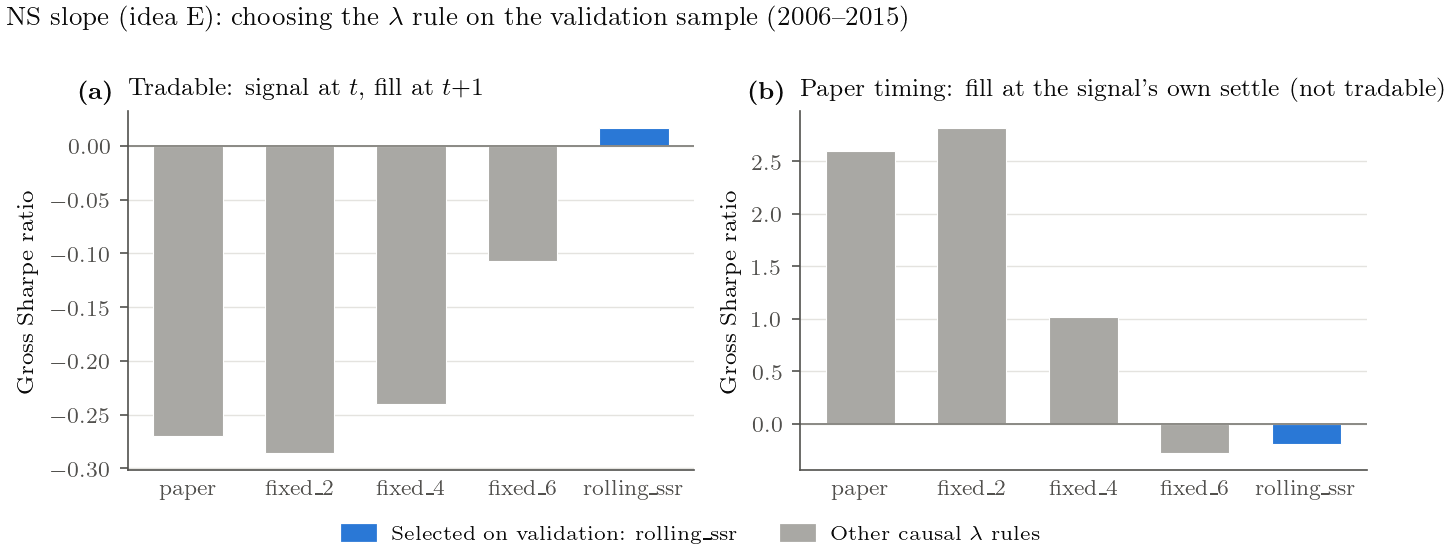

In [10]:
fig = F.lambda_validation(lam_table, CHOSEN, STRATEGY, "2006–2015")
ps.save(fig, "ns_lambda_validation");

## 4. 时点：信号能不能扛过一天的执行延迟

固定 t 日的 1st/4th pair，比较四个窗口的 signed spread return：`[t, t+1]` 是论文时点（同一个 settle 出信号又成交，**不可交易**），`[t+1, t+2]` 是我们可交易的第一天。

三个信号：论文 λ 的 ΔβS、validation 选出的 λ 的 ΔβS、不用 NS 的 ΔS = Δ(F¹ − F⁴)（论文 Table 10）。

In [11]:
W = [(0, 1), (1, 2), (2, 3), (1, 6)]
slope_bench = ns.build_slope_strategy(contract, mk, rule="paper", score="dS")
signals_ = {
    r"NS $\Delta\beta_S$, paper $\lambda$": base,
    rf"NS $\Delta\beta_S$, selected $\lambda$ ({CHOSEN.replace('_', ' ')})": strategies[CHOSEN]["st"],
    r"No NS: $\Delta(F^1-F^4)$": slope_bench,
}
profiles = {name: horizon.horizon_profile(horizon.forward_returns(s["pairs"], mk, horizons=W), s["signal"])
            for name, s in signals_.items()}
display(pd.concat({k: v.set_index("horizon")[["mean_bps", "t_nw", "hit_rate"]] for k, v in profiles.items()}, axis=1).round(3))

NS $\Delta\beta_S$, paper $\lambda$                 NS $\Delta\beta_S$, selected $\lambda$ (rolling ssr)                 No NS: $\Delta(F^1-F^4)$          \
                                    mean_bps   t_nw hit_rate                                             mean_bps   t_nw hit_rate                 mean_bps    t_nw   
horizon                                                                                                                                                              
t+0->t+1                               2.655  8.101    0.496                                              0.217    0.667    0.481                    3.601  10.421   
t+1->t+2                              -0.043 -0.126    0.481                                              0.008    0.024    0.481                    0.276   0.744   
t+2->t+3                              -0.174 -0.500    0.484                                             -0.255   -0.751    0.482                   -0.266  -0.750   
t+1->t+6                              -1.265 -1.833    0.497                                             -0.693   -1.037    0.496                   -1.073  -1.389   

                   
         hit_rate  
horizon            
t+0->t+1    0.504  
t+1->t+2    0.484  
t+2->t+3    0.484  
t+1->t+6    0.497

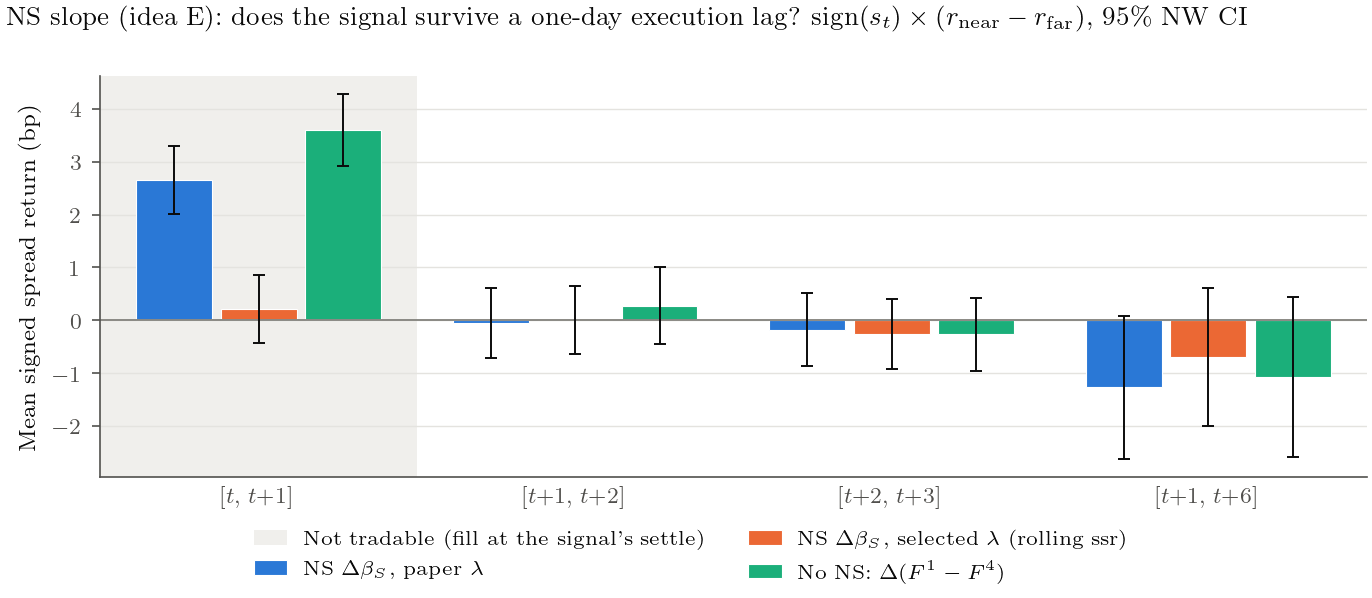

In [12]:
fig = F.timing_comparison(profiles, STRATEGY)
ps.save(fig, "ns_timing");

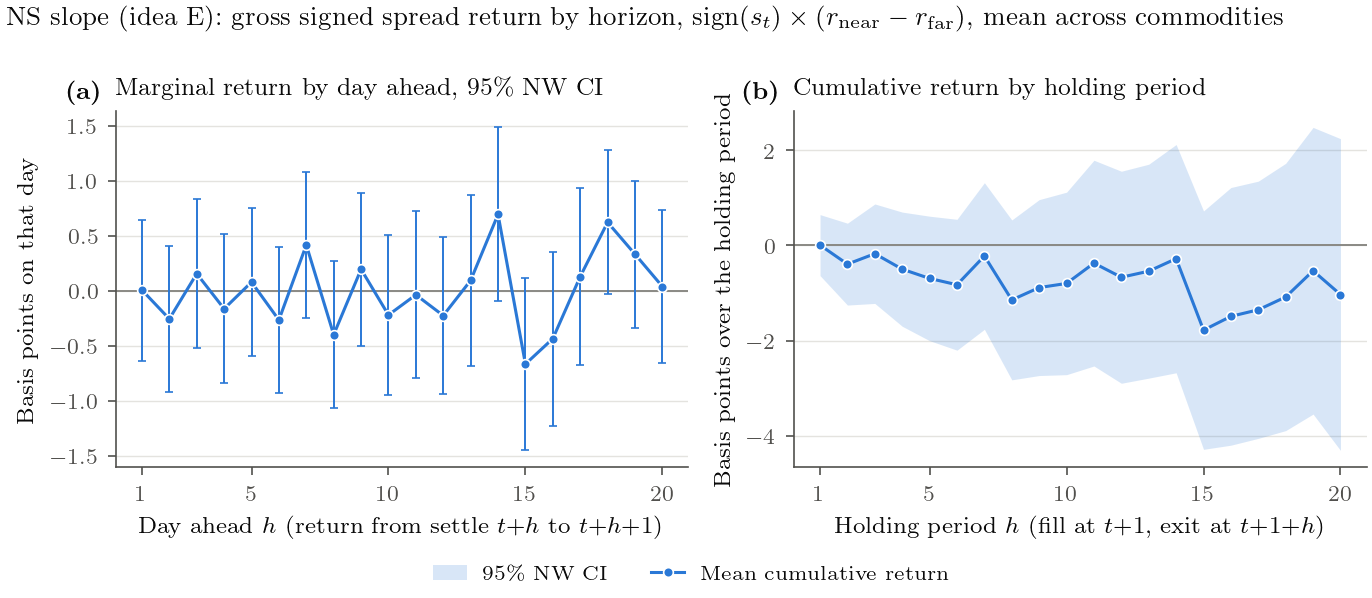

In [13]:
chosen = strategies[CHOSEN]["st"]
marg = horizon.horizon_profile(horizon.forward_returns(chosen["pairs"], mk, horizons=horizon.marginal_horizons(20)), chosen["signal"])
cum = horizon.horizon_profile(horizon.forward_returns(chosen["pairs"], mk, horizons=horizon.cumulative_horizons(20)), chosen["signal"])
fig = F.horizon_decay(marg, cum, STRATEGY)
ps.save(fig, "ns_horizon_decay");

## 5. 复现论文样本（21 个商品，1992-01 至 2019-06）

论文报告 S 策略 gross 年化 1.77%、Sharpe 1.41（t = 7.23），net Sharpe 0.44–1.04。这里用论文的 λ、论文的商品池和样本期，分别给出：

- **论文时点**的 gross（不可交易，只作复现对照）；
- **可交易**回测（t+1 成交）：gross、论文的成本情景 TC1–TC3，以及 v2 的三层成本。

权重口径：每个活跃商品 gross 1/N、两腿等名义，和论文 $|w_1|=|w_4|=1/(2N)$ 一致；论文多空两侧各 50% 的约束不强加。

In [14]:
paper_st = ns.build_slope_strategy(contract, mk, rule="paper", roots=ns.PAPER_ROOTS)
paper_fwd = horizon.forward_returns(paper_st["pairs"], mk, horizons=[(0, 1), (1, 2)])
paper_legs = sizing.legs_from_signal(paper_st["signal"], paper_st["pairs"])
rows = {"paper (reported)": dict(ann_ret_pct=1.77, sharpe=1.41, t_nw=7.23)}
rows["ours, paper timing (not tradable)"] = report.return_summary(
    report.execution_free_returns(paper_fwd, paper_st["signal"], "fwd_0_1"), *PAPER_SAMPLE)
for name, cost in [("v2 costs", CFG.cost)] + list(costs.paper_scenarios().items()):
    r = simulate.simulate(paper_legs, mk, simulate.SimConfig(capital=1e6, cost=cost))
    perf = report.performance_table(r, *PAPER_SAMPLE).set_index("layer")
    if name == "v2 costs":
        rows["ours, tradable gross"] = perf.loc["gross"].to_dict()
        rows["ours, tradable net (v2: spread+fee+impact)"] = perf.loc["- impact (all)"].to_dict()
        paper_tradable = r
    else:
        rows[f"ours, tradable net {name}"] = perf.loc["- impact (all)"].to_dict()
replication = pd.DataFrame(rows).T[["ann_ret_pct", "sharpe", "t_nw", "turnover_x"]]
display(replication.round(3))

,ann_ret_pct,sharpe,t_nw,turnover_x
paper (reported),1.770,1.410,7.230,NaN
"ours, paper timing (not tradable)",3.551,2.032,10.950,NaN
"ours, tradable gross",-0.183,-0.114,-0.632,219.718
"ours, tradable net (v2: spread+fee+impact)",-9.279,-5.529,-27.989,219.718
"ours, tradable net TC1",-0.827,-0.515,-2.858,219.718
"ours, tradable net TC2",-2.018,-1.255,-6.950,219.718
"ours, tradable net TC3",-1.921,-1.196,-6.627,219.718


### 5b. 就按论文的时点做，扣完成本还赚钱吗

**怎么算**：`simulate.same_settle` 把每个目标仓位的日期往前挪一个交易日。引擎的规则是"日期 d 的目标在下一个交易日成交"，挪完之后就在**信号自己的 settle** 成交，第一笔 P&L 是 t → t+1——正是论文的口径。其余全部照 v2：持有合约数、P&L = 合约数 × point value × Δsettle、收益 = P&L / \$1m、成本按每条腿实际成交的张数计。

- 论文样本（21 个商品，1992–2019）、论文 λ；
- v2 三层成本（half-spread 0.5 tick、挂牌 spread 一次跨价差；fee \$1.5；impact），以及论文的 TC1–TC3（每边 \$0.75；0.835 bp；\$0.75 + 1/8 tick，没有 bid-ask）。

再强调一次：这是**诊断**，settle 公布之后不能再按它成交；就算用 TAS（trade at settlement）也得在 settle 公布之前下单，那时还没有这个信号。

In [15]:
paper_same = simulate.same_settle(paper_legs, mk)
res_same = simulate.simulate(paper_same, mk, CFG)
same_rows = {f"v2 {k}": v for k, v in report.performance_table(res_same, *PAPER_SAMPLE).set_index("layer").iterrows()}
for name, cost in costs.paper_scenarios().items():
    r = simulate.simulate(paper_same, mk, simulate.SimConfig(capital=1e6, cost=cost))
    same_rows[f"paper {name}"] = report.performance_table(r, *PAPER_SAMPLE).set_index("layer").loc["- impact (all)"]
same_table = pd.DataFrame(same_rows).T[["ann_ret_pct", "ann_vol_pct", "sharpe", "t_nw", "turnover_x", "cost_bps_yr"]]
years = report.return_summary(res_same.daily.set_index("date")["ret_gross"], *PAPER_SAMPLE)["days"] / 252
same_table["sharpe_x_sqrt_years"] = same_table["sharpe"] * np.sqrt(years)
display(same_table.round(3))

,ann_ret_pct,ann_vol_pct,sharpe,t_nw,turnover_x,cost_bps_yr,sharpe_x_sqrt_years
v2 gross,3.108,1.591,1.953,10.765,224.472,0.000,10.358
v2 - half-spread,-0.036,1.627,-0.022,-0.122,224.472,314.417,-0.117
v2 - fees,-1.352,1.644,-0.822,-4.443,224.472,445.976,-4.359
v2 - impact (all),-5.887,1.744,-3.375,-17.098,224.472,899.495,-17.899
paper TC1,2.450,1.598,1.533,8.446,224.472,65.780,8.130
paper TC2,1.233,1.610,0.766,4.226,224.472,187.434,4.062
paper TC3,1.332,1.610,0.827,4.544,224.472,177.622,4.386


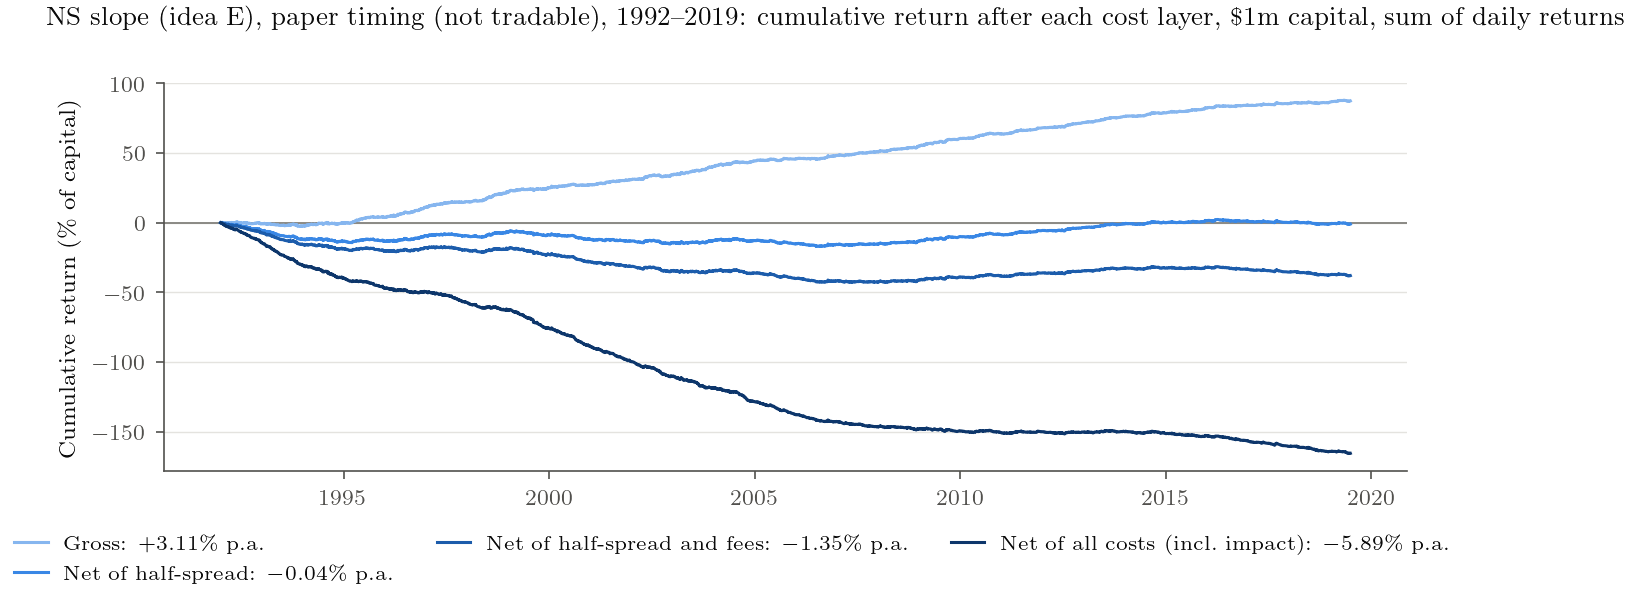

In [16]:
fig = F.nav_by_cost_layer(res_same, STRATEGY + ", paper timing (not tradable), 1992--2019",
                          test_start=None, start=PAPER_SAMPLE[0], end=PAPER_SAMPLE[1])
ps.save(fig, "ns_nav_paper_timing");

**Sharpe 和 t 值为什么不相等**：两者的零假设都是 0，分子都是"均值 / 标准差"，区别在时间尺度。

- 年化 Sharpe = $\dfrac{\bar r}{\hat\sigma}\sqrt{252}$：单位时间的收益质量，和样本长短无关。
- t 值 = $\dfrac{\bar r}{\hat\sigma/\sqrt{T}} = \dfrac{\bar r}{\hat\sigma}\sqrt{T}$，T 是天数：所以 $t \approx \text{Sharpe}\times\sqrt{T/252} = \text{Sharpe}\times\sqrt{\text{年数}}$。

上表最后一列 `sharpe_x_sqrt_years` 就是这个近似；它和 `t_nw` 的差来自 Newey–West 对日收益自相关的修正（这里用 5 阶滞后）。论文样本 27.5 年，√27.5 ≈ 5.2：Sharpe 2 对应 t ≈ 10。Sharpe 回答"这个策略好不好"，t 回答"在这么长的样本里能不能排除 0"。

### 5c. 用 k 天平滑省成本，能不能把它救回来

上面已经看到 edge 只活一天、之后略有反转。问题是：如果按论文时点 gross 能赚、扣成本不赚，那把仓位做成过去 k 天信号的平均（每天只调 1/k），换手下降能不能省出钱来？可交易时点（t+1 成交）也做一遍。

论文样本、论文 λ、\$1m；k = 1, 2, 3, 5, 10, 20。图里 (b) 是 gross，(c) 是扣 half-spread 和 fee 之后（一阶成本）。

In [17]:
K_GRID = [1, 2, 3, 5, 10, 20]
k_timing = {
    "Paper timing: fill at the signal's settle (not tradable)": report.k_sweep(
        paper_st["signal"], paper_st["pairs"], mk, K_GRID, CFG, same_settle=True, start=PAPER_SAMPLE[0], end=PAPER_SAMPLE[1]),
    "Tradable: fill at the next settle": report.k_sweep(
        paper_st["signal"], paper_st["pairs"], mk, K_GRID, CFG, start=PAPER_SAMPLE[0], end=PAPER_SAMPLE[1]),
}
show = ["k", "turnover_x", "ret_gross", "t_gross", "ret_- half-spread", "ret_- fees", "t_- fees", "ret_- impact (all)"]
display(pd.concat({name.split(":")[0]: t[show].set_index("k") for name, t in k_timing.items()}, axis=1).round(3))

Paper timing                                                                              Tradable                                                          \
     turnover_x ret_gross t_gross ret_- half-spread ret_- fees t_- fees ret_- impact (all) turnover_x ret_gross t_gross ret_- half-spread ret_- fees t_- fees   
k                                                                                                                                                               
1       224.472     3.108  10.765            -0.036     -1.352   -4.443             -5.887    219.718    -0.183  -0.632            -3.286     -4.574  -15.487   
2       170.952     2.127   6.943            -0.237     -1.222   -3.888             -3.813    168.965    -0.300  -0.929            -2.666     -3.642  -11.085   
3        80.743     0.985   5.516            -0.121     -0.584   -3.230             -0.980     79.883    -0.260  -1.355            -1.367     -1.825   -9.424   
5        49.737     0.515   3.628            -0.170     -0.455   -3.187             -0.558     49.247    -0.319  -2.158            -1.004     -1.287   -8.673   
10       29.096     0.222   2.141            -0.178     -0.344   -3.313             -0.368     28.744    -0.213  -1.927            -0.612     -0.776   -7.018   
20       15.337     0.208   2.993            -0.002     -0.090   -1.288             -0.094     15.166    -0.001  -0.011            -0.210     -0.296   -4.014   

                       
   ret_- impact (all)  
k                      
1              -9.279  
2              -6.407  
3              -2.251  
5              -1.394  
10             -0.800  
20             -0.301

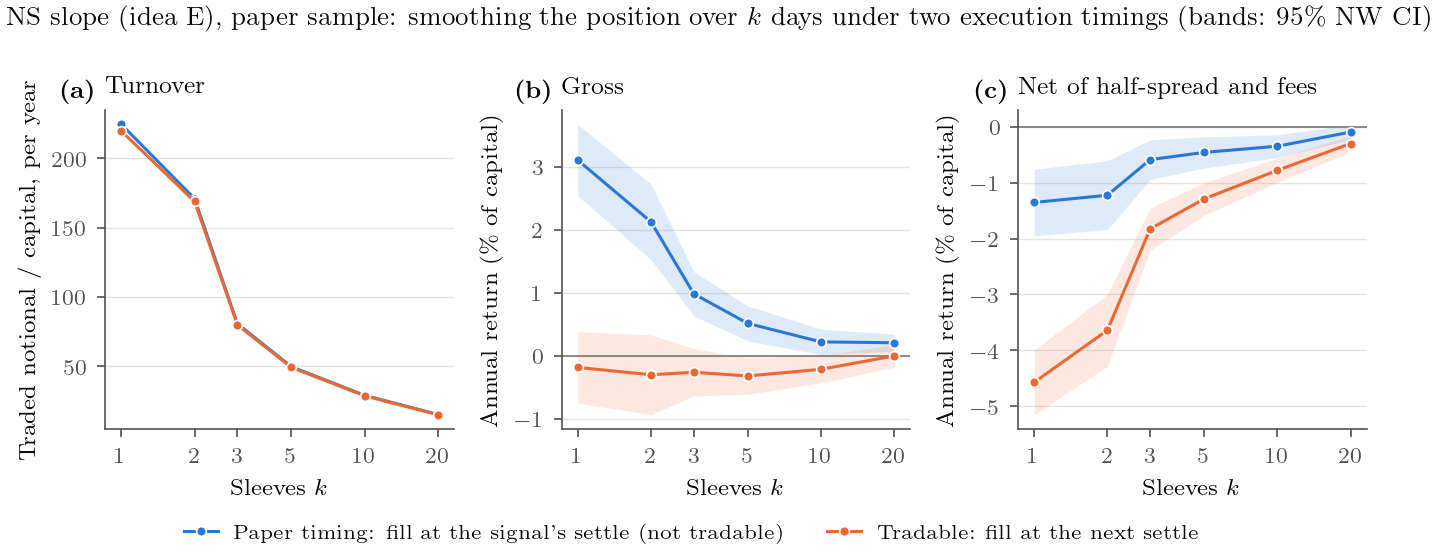

In [18]:
fig = F.k_sweep_timing(k_timing, STRATEGY + ", paper sample")
ps.save(fig, "ns_k_sweep_timing");

## 6. 全样本可交易回测（选出的 λ）

24 个商品、1986–2026、t+1 成交、日频（信号不变就持有，不额外交易）、等权、\$1m。分 full / train / test 报 v2 的四层。

In [19]:
res = strategies[CHOSEN]["res"]
perf = pd.concat({
    "full": report.performance_table(res),
    "train 1986-2015": report.performance_table(res, end="2015-12-31"),
    "test 2016-2026": report.performance_table(res, start=TEST_START),
}, names=["period"])
display(perf)

layer  ann_ret_pct  ann_vol_pct  sharpe    t_nw  max_dd_pct  turnover_x  cost_bps_yr
period                                                                                                          
full            0           gross       -0.071        2.830  -0.025  -0.197     -19.440     231.711        0.000
                1   - half-spread       -3.394        2.835  -1.197  -9.340    -143.889     231.711      332.300
                2          - fees       -4.797        2.839  -1.689 -13.107    -201.173     231.711      472.588
                3  - impact (all)       -9.772        2.910  -3.358 -23.708    -407.009     231.711      970.132
train 1986-2015 0           gross       -0.149        2.158  -0.069  -0.360     -19.440     233.642        0.000
                1   - half-spread       -3.986        2.165  -1.841  -9.557    -125.652     233.642      383.769
                2          - fees       -5.573        2.171  -2.567 -13.265    -172.983     233.642      542.428
                3  - impact (all)      -11.862        2.280  -5.202 -24.674    -363.874     233.642     1171.305
test 2016-2026  0           gross        0.145        4.160   0.035   0.199     -11.190     226.362        0.000
                1   - half-spread       -1.753        4.161  -0.421  -2.400     -19.480     226.362      189.772
                2          - fees       -2.647        4.162  -0.636  -3.617     -29.200     226.362      279.189
                3  - impact (all)       -3.986        4.164  -0.957  -5.407     -43.981     226.362      413.041

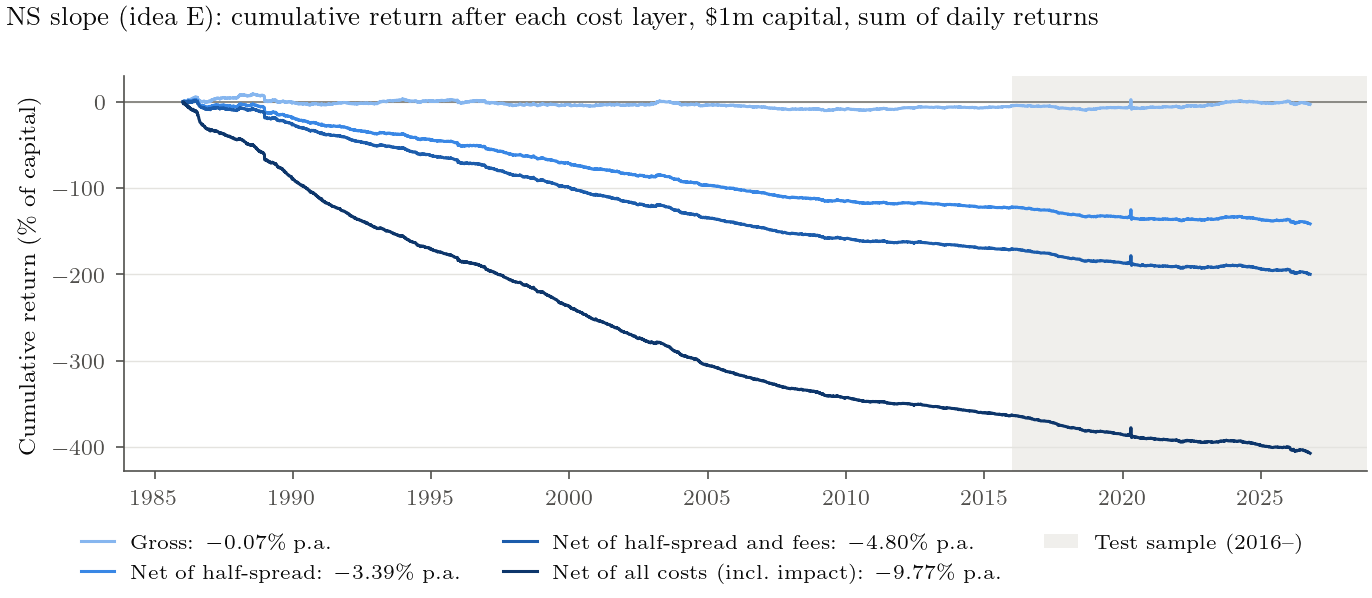

In [20]:
fig = F.nav_by_cost_layer(res, STRATEGY)
ps.save(fig, "ns_nav_by_cost_layer");

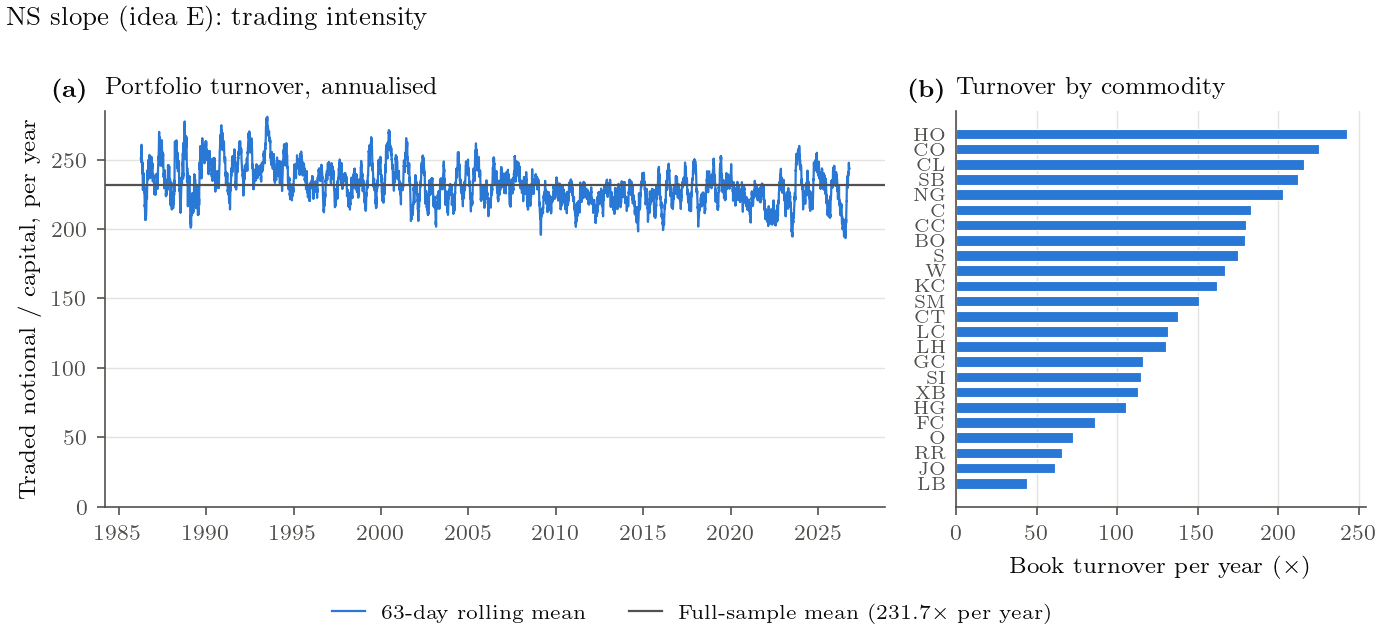

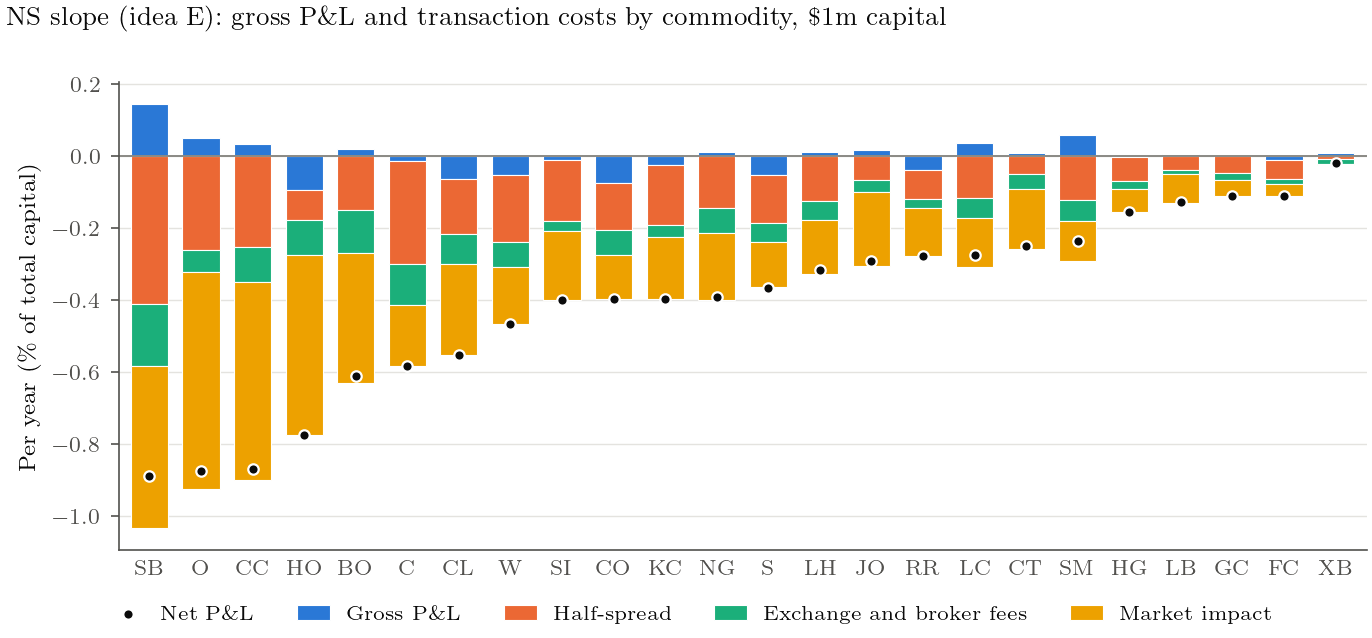

In [21]:
fig = F.turnover(res, STRATEGY)
ps.save(fig, "ns_turnover")
fig = F.commodity_pnl_and_costs(res, STRATEGY)
ps.save(fig, "ns_pnl_and_costs_by_commodity");

## 7. C 策略：curvature 的 butterfly

ΔβC > 0 → 空 1st、多 2nd（两倍名义）、空 4th，名义 1:2:1；否则反向。同样 t+1 成交、持有一天。流动性 flag 沿用 S 的（1st 和 4th）。

In [22]:
sig_c = chosen["sig"].merge(chosen["pairs"][["date", "root", "liquid"]], on=["date", "root"], how="left")
sig_c.loc[~sig_c["liquid"].fillna(False).astype(bool), "dbC"] = np.nan
res_c = simulate.simulate(ns.butterfly_legs(sig_c, chosen["curve"]), mk, CFG)
display(pd.concat({
    "full": report.performance_table(res_c),
    "test 2016-2026": report.performance_table(res_c, start=TEST_START),
}, names=["period"]))

layer  ann_ret_pct  ann_vol_pct  sharpe    t_nw  max_dd_pct  turnover_x  cost_bps_yr
period                                                                                                         
full           0           gross       -0.320        1.308  -0.245  -1.930     -20.165     235.771        0.000
               1   - half-spread       -3.551        1.318  -2.695 -20.508    -148.394     235.771      323.142
               2          - fees       -4.983        1.324  -3.762 -28.007    -207.898     235.771      466.256
               3  - impact (all)       -8.413        1.407  -5.979 -36.683    -350.438     235.771      809.343
test 2016-2026 0           gross       -0.001        1.846  -0.001  -0.004      -4.833     228.068        0.000
               1   - half-spread       -1.882        1.848  -1.018  -6.311     -20.934     228.068      188.044
               2          - fees       -2.784        1.850  -1.505  -9.304     -30.820     228.068      278.250
               3  - impact (all)       -3.834        1.854  -2.067 -12.526     -42.426     228.068      383.253

## 8. 每个商品的 IC 显著吗：block bootstrap

每个商品自己的时间序列上，ΔβS 和可交易窗口 `[t+1, t+2]` 的 spread return 的 Spearman IC；21 天块的 moving-block bootstrap，2000 次。作对照，也给论文时点 `[t, t+1]` 的显著个数。

In [23]:
fwd_c = horizon.forward_returns(chosen["pairs"], mk, horizons=[(0, 1), (1, 2)])
boot_sig = chosen["signal"].loc[chosen["signal"]["target"].ne(0)]
boot_trad, draws_trad = horizon.block_bootstrap_ic(fwd_c, boot_sig, col="fwd_1_2", score_col="score", block=21, n_boot=2000)
boot_paper, _ = horizon.block_bootstrap_ic(fwd_c, boot_sig, col="fwd_0_1", score_col="score", block=21, n_boot=2000)
print(f"p < 0.05, tradable [t+1, t+2]: {(boot_trad['p_value'] < 0.05).sum()} of {len(boot_trad)}; "
      f"paper timing [t, t+1]: {(boot_paper['p_value'] < 0.05).sum()} of {len(boot_paper)}")
display(boot_trad.sort_values("ic").round(3).T)

p < 0.05, tradable [t+1, t+2]: 6 of 24; paper timing [t, t+1]: 10 of 24


,4,22,3,8,18,7,0,6,23,17,1,5,11,21,9,2,12,14,16,13,20,10,15,19
root,CO,W,CL,HG,S,GC,BO,FC,XB,RR,C,CT,KC,SM,HO,CC,LB,LH,O,LC,SI,JO,NG,SB
ic,-0.041,-0.036,-0.033,-0.032,-0.031,-0.022,-0.019,-0.017,-0.014,-0.013,-0.012,-0.004,-0.003,-0.0,-0.0,0.0,0.0,0.005,0.007,0.008,0.01,0.011,0.013,0.022
ci_lo,-0.065,-0.061,-0.05,-0.063,-0.057,-0.053,-0.047,-0.055,-0.041,-0.057,-0.037,-0.034,-0.03,-0.028,-0.02,-0.023,-0.052,-0.023,-0.026,-0.02,-0.023,-0.034,-0.01,0.0
ci_hi,-0.018,-0.011,-0.012,-0.001,-0.005,0.007,0.008,0.021,0.018,0.031,0.013,0.024,0.022,0.029,0.023,0.026,0.058,0.031,0.042,0.034,0.041,0.062,0.035,0.042
p_value,0.0,0.004,0.0,0.038,0.015,0.137,0.176,0.372,0.418,0.556,0.327,0.716,0.799,0.993,0.935,0.99,0.919,0.727,0.73,0.595,0.591,0.624,0.294,0.047
n,7776,6375,8439,4142,6641,4601,6157,3119,4487,2426,7240,5331,6161,5813,8673,6654,1333,5373,2813,5396,4435,1928,7713,8719


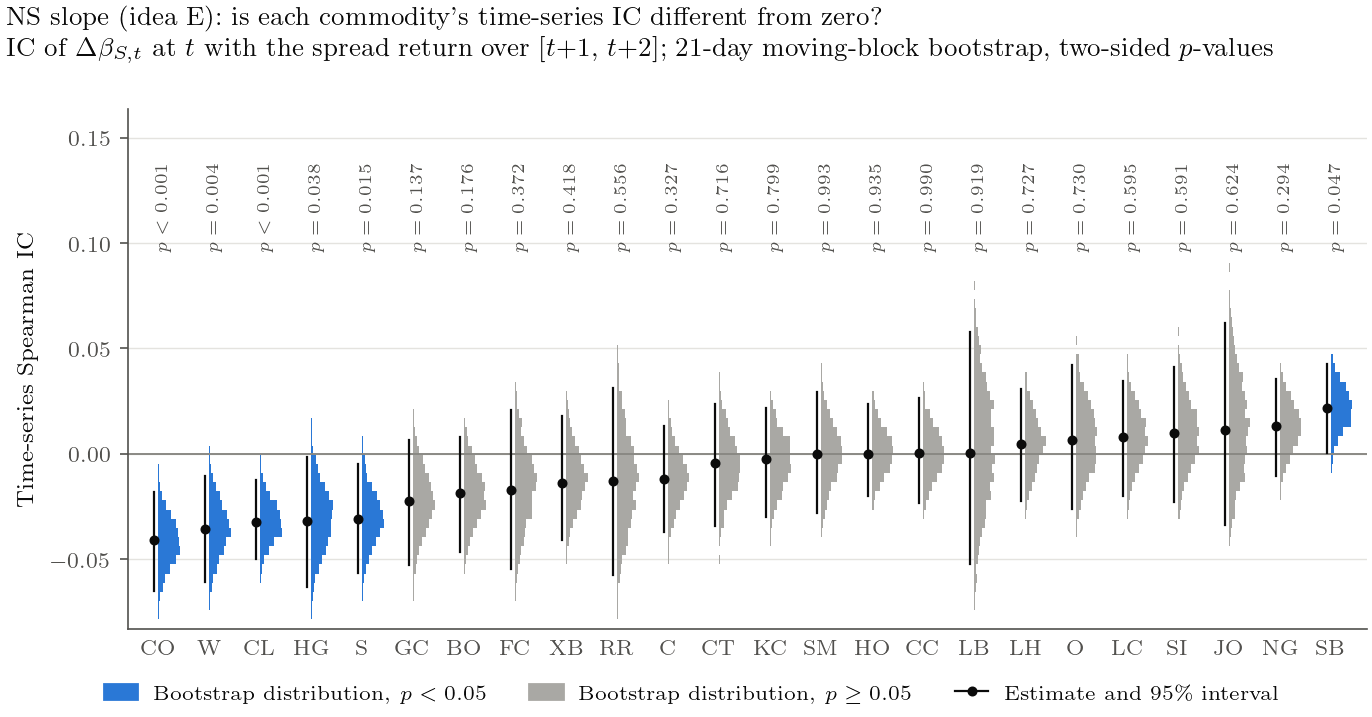

In [24]:
fig = F.bootstrap_ic_distribution(boot_trad, draws_trad, STRATEGY, r"$\Delta\beta_{S,t}$",
                                  r"$[t{+}1,\,t{+}2]$", block=21)
ps.save(fig, "ns_bootstrap_ic");

## 9. k 天平滑（≈ 论文 Table 9 的 MA3/MA5）

仓位 = 过去 k 天 target 的平均。论文用 3/5 日均值平滑信号，Sharpe 从 1.41 降到约 1.0（论文时点）。这里看可交易时点下换手和各层收益怎么随 k 变。

In [25]:
ks = report.k_sweep(chosen["signal"], chosen["pairs"], mk, ks=[1, 2, 3, 5, 10, 20], config=CFG)
display(ks[["k", "turnover_x", "ret_gross", "t_gross", "ret_- fees", "ret_- impact (all)"]].round(3))

,k,turnover_x,ret_gross,t_gross,ret_- fees,ret_- impact (all)
0,1,231.711,-0.071,-0.197,-4.797,-9.772
1,2,180.189,-0.120,-0.349,-3.733,-6.666
2,3,80.864,-0.013,-0.061,-1.617,-2.100
3,5,50.069,-0.094,-0.567,-1.089,-1.243
4,10,29.956,-0.037,-0.316,-0.630,-0.669
5,20,15.399,0.007,0.094,-0.297,-0.305


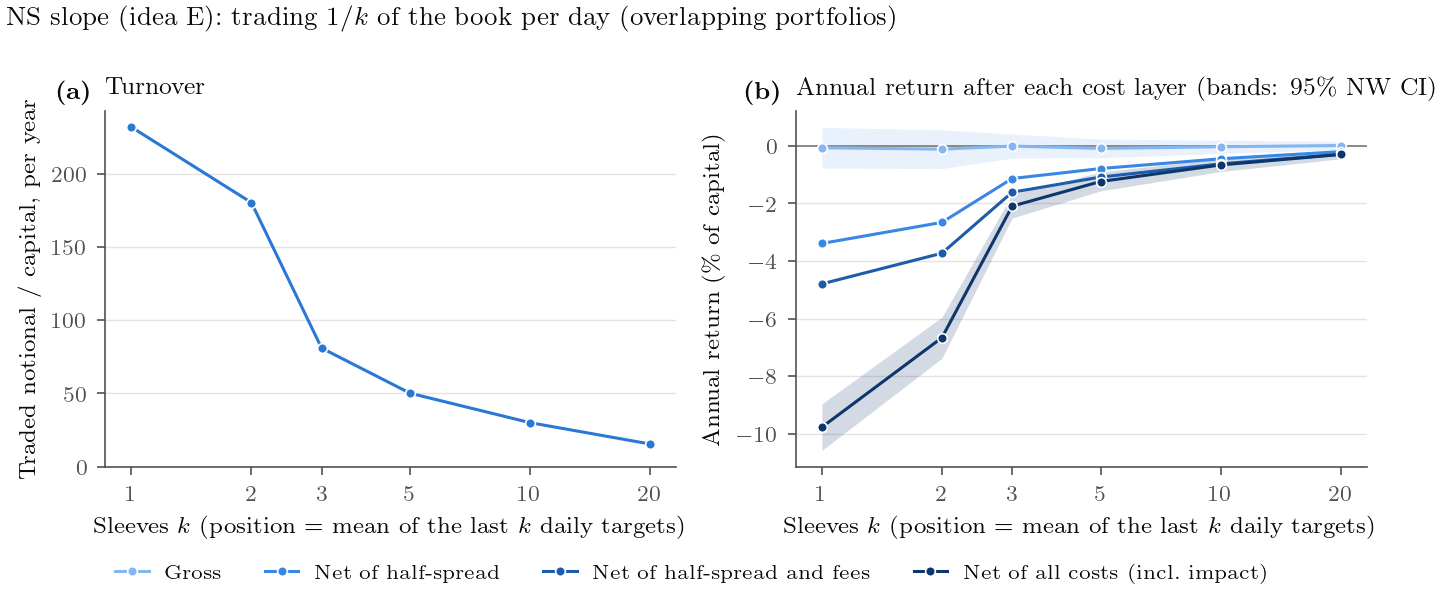

In [26]:
fig = F.k_sweep(ks, STRATEGY)
ps.save(fig, "ns_k_sweep");

## 10. 资本：\$100k–\$10m，以及整手

小数张合约下，资本只影响 impact（第 7 节逻辑同 06）。但小资本时很多商品**买不了一手**：`round_lots=True` 时每条腿四舍五入到整数张，不足半手的 spread 不建。下面比较 \$100k 和 \$1m 下有多少 root-day 真的建了仓。

In [27]:
cap = report.capacity_curve(res, capitals=[1e5, 3e5, 1e6, 3e6, 1e7])
display(cap.round(3))
legs_chosen = sizing.legs_from_signal(chosen["signal"], chosen["pairs"])
lot_rows = {}
for c in (1e5, 1e6):
    r = simulate.simulate(legs_chosen, mk, simulate.SimConfig(capital=c, round_lots=True))
    held = r.by_root.loc[r.by_root["gross_notional"] > 0]
    lot_rows[f"${c / 1e6:g}m, whole lots"] = dict(
        root_days_held=len(held), roots_ever_held=held["root"].nunique(),
        **report.performance_table(r).set_index("layer").loc["- impact (all)", ["ann_ret_pct", "turnover_x"]].to_dict())
lot_rows["$1m, fractional"] = dict(root_days_held=int((res.by_root["gross_notional"] > 0).sum()),
                                  roots_ever_held=res.by_root.loc[res.by_root["gross_notional"] > 0, "root"].nunique(),
                                  **report.performance_table(res).set_index("layer").loc["- impact (all)", ["ann_ret_pct", "turnover_x"]].to_dict())
display(pd.DataFrame(lot_rows).T.round(3))

,capital,gross_bps_yr,half_spread_bps_yr,fee_bps_yr,impact_bps_yr,ann_ret_pct,sharpe
0,100000.0,-7.081,332.3,140.289,17.894,-4.976,-1.750
1,300000.0,-7.081,332.3,140.289,122.050,-6.017,-2.106
2,1000000.0,-7.081,332.3,140.289,497.543,-9.772,-3.358
3,3000000.0,-7.081,332.3,140.289,1123.922,-16.036,-5.287
4,10000000.0,-7.081,332.3,140.289,2250.129,-27.298,-8.047


,root_days_held,roots_ever_held,ann_ret_pct,turnover_x
"$0.1m, whole lots",2957.0,17.0,-4.305,95.945
"$1m, whole lots",105654.0,24.0,-9.867,204.793
"$1m, fractional",137288.0,24.0,-9.772,231.711


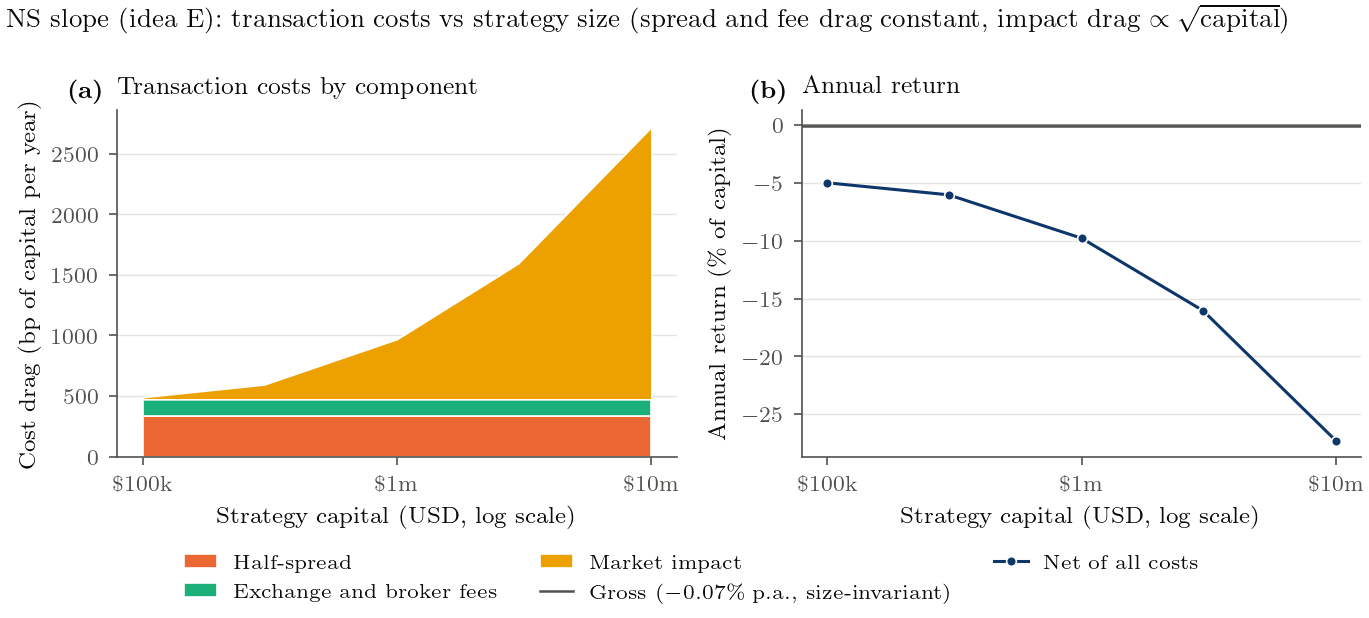

In [28]:
fig = F.capacity(cap, STRATEGY)
ps.save(fig, "ns_capacity");

## 11. 扩展：Kalman dynamic NS，和 OLS 做 A/B

状态 β_t = β_{t−1} + η_t（随机游走，等于每天把拟合向昨天的 β 收缩），观测 F_t = X_t(λ_t) β_t + ε_t；有 3 或 4 张 eligible 合约就更新（D-016 item 2）。价格水平跨几十年变化很大，所以 R_t = r·s²_{t−1}·I、Q_t = q·s²_{t−1}·I，s 是前一天曲线均价。(r, q) 按品种在 **1986–2005** 上用一步预测的对数似然选（网格），A/B 在 **2006 以后**做，全部因果。

**A/B 怎么比才公平**：OLS 本来就最小化样本内残差，所以不比样本内 R²。比两件样本外的事，同一天配对、21 天块 bootstrap：

- **一步预测**：用 t−1 及以前的信息预测 t 日整条曲线。OLS = 昨天的 β（随机游走），Kalman = β_{t|t−1}。
- **留一张合约（LOO）**：当天留出一张，OLS 用另外 3 张拟合，Kalman 用另外 3 张更新先验，预测被留出的那张。注意 Kalman 的先验里有"昨天这张合约的价格"，OLS 没有——这是合法的因果信息，但意味着 LOO 这里比的更多是"用不用历史"。

标准：**大多数商品显著改进才用**（Kalman 结构更复杂）。最后再看交易：用 Kalman 的 ΔβS 做同样的 1st/4th spread。

In [29]:
from src import ns_kalman as nk

kf = nk.kalman_panel(base["curve"], select_end="2005-12-31")
ab = nk.ab_table(kf, nk.ols_one_step(base["fits"], base["wide"], base["curve"]), quality, start="2006-01-01")
ab_tests = {name: horizon.block_bootstrap_mean(ab, col, block=21, n_boot=2000, stat="median")
            for name, col in [("one-step forecast R2", "gain_pred"), ("leave-one-out R2", "gain_loo")]}
display(pd.DataFrame({name: {"Kalman better (p<0.05)": int(((s["p_value"] < 0.05) & (s["mean"] > 0)).sum()),
                             "Kalman worse (p<0.05)": int(((s["p_value"] < 0.05) & (s["mean"] < 0)).sum()),
                             "median of root medians": s["mean"].median()} for name, (s, _d) in ab_tests.items()}).round(3))
display(ab[["r2_pred_ols", "r2_pred_kf", "loo_LSC", "loo_kf"]].median().round(3).to_frame("median").T)

,one-step forecast R2,leave-one-out R2
Kalman better (p<0.05),1.000,24.000
Kalman worse (p<0.05),20.000,0.000
median of root medians,-0.004,0.198


,r2_pred_ols,r2_pred_kf,loo_LSC,loo_kf
median,0.528,0.454,0.724,0.951


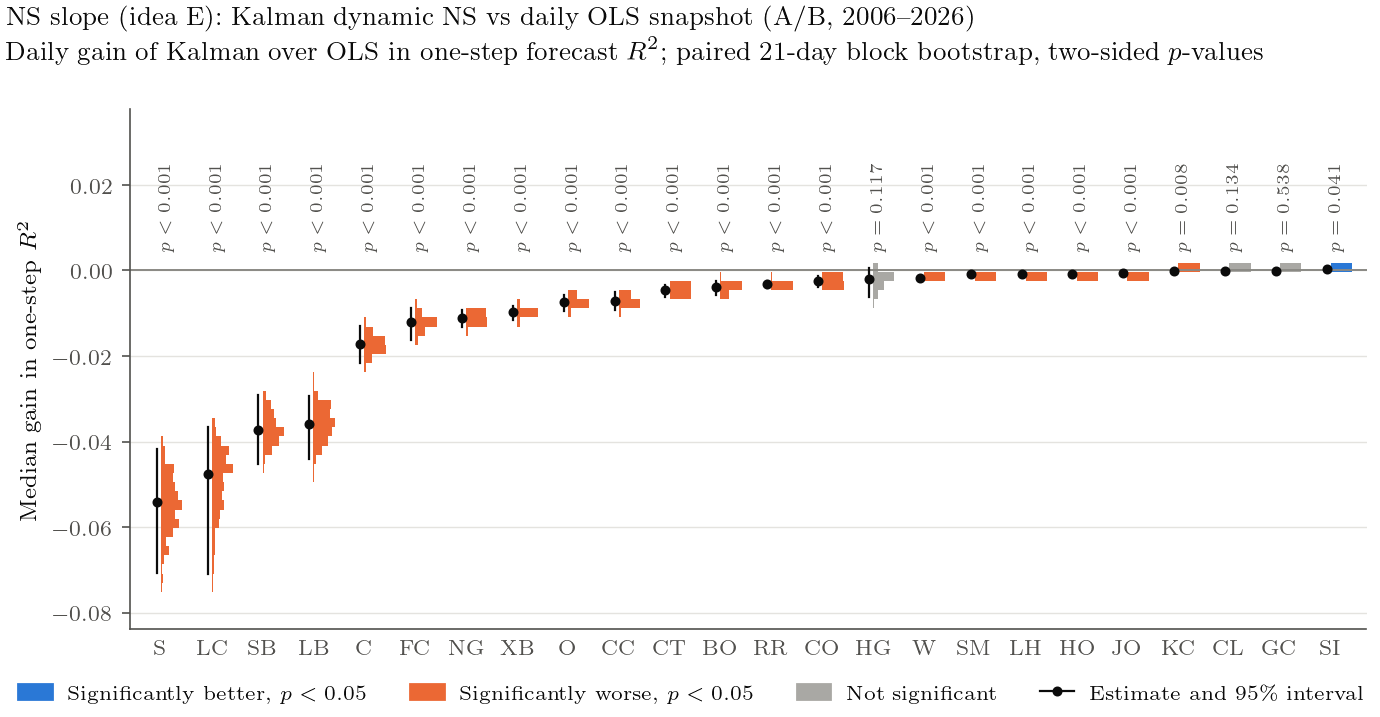

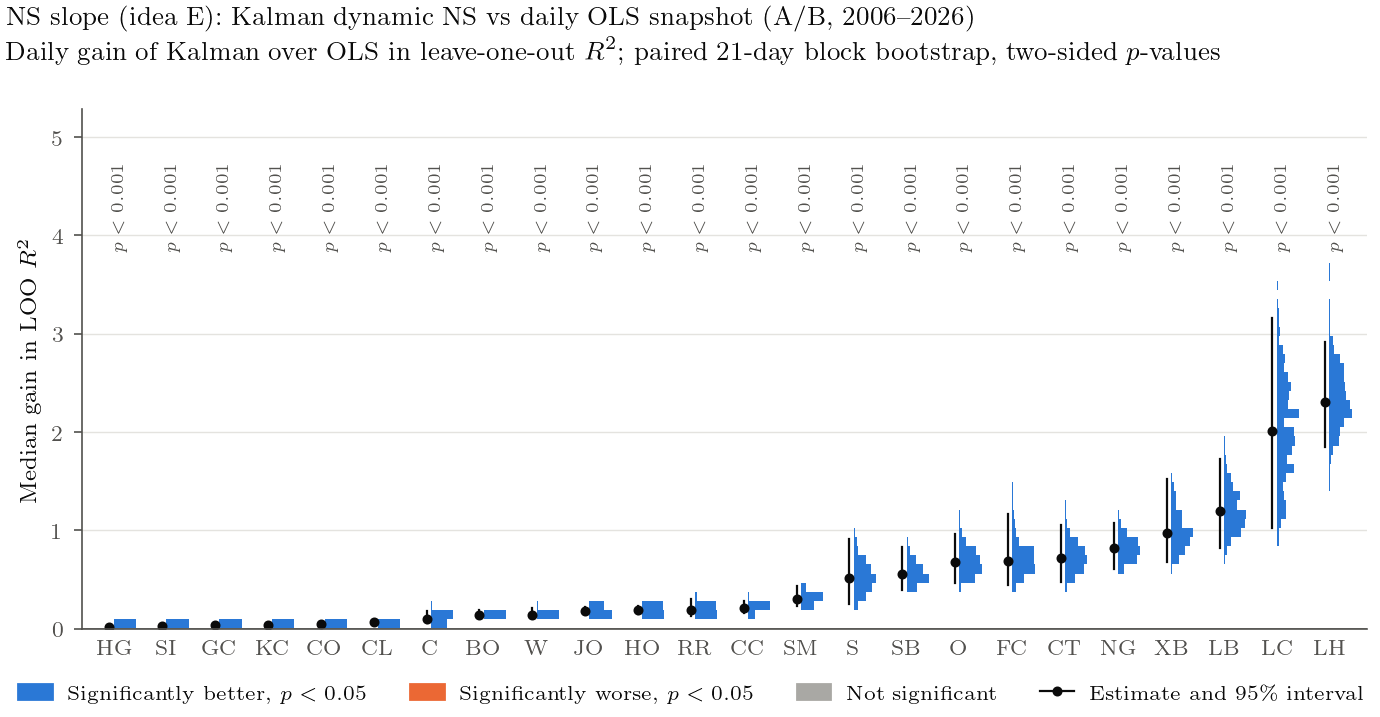

In [30]:
for name, ylabel, fname in [("one-step forecast R2", r"Median gain in one-step $R^2$", "ns_kalman_ab_forecast"),
                             ("leave-one-out R2", r"Median gain in LOO $R^2$", "ns_kalman_ab_loo")]:
    s, d = ab_tests[name]
    title = ps.tex(f"{STRATEGY}: Kalman dynamic NS vs daily OLS snapshot (A/B, 2006--2026)" + "\n"
                   + f"Daily gain of Kalman over OLS in {name.replace('R2', '$R^2$')}; paired 21-day block bootstrap, two-sided $p$-values")
    fig = F.bootstrap_distribution(s, d, "mean", ylabel, title, signed=True)
    ps.save(fig, fname)

In [31]:
kalman_st = nk.build_kalman_strategy(base, kf, mk)
trade_ab = {}
for name, s in {"OLS snapshot": base, "Kalman DNS": kalman_st}.items():
    prof = horizon.horizon_profile(horizon.forward_returns(s["pairs"], mk, horizons=[(0, 1), (1, 2), (1, 6)]), s["signal"]).set_index("horizon")
    perf = report.performance_table(simulate.simulate(sizing.legs_from_signal(s["signal"], s["pairs"]), mk, CFG)).set_index("layer")
    trade_ab[name] = {"[t,t+1] bp (not tradable)": prof.loc["t+0->t+1", "mean_bps"], "t": prof.loc["t+0->t+1", "t_nw"],
                      "[t+1,t+2] bp": prof.loc["t+1->t+2", "mean_bps"], "t ": prof.loc["t+1->t+2", "t_nw"],
                      "tradable gross %/yr": perf.loc["gross", "ann_ret_pct"], "t gross": perf.loc["gross", "t_nw"],
                      "net of spread+fees %/yr": perf.loc["- fees", "ann_ret_pct"], "turnover x": perf.loc["gross", "turnover_x"]}
display(pd.DataFrame(trade_ab).T.round(3))

,"[t,t+1] bp (not tradable)",t,"[t+1,t+2] bp",t,tradable gross %/yr,t gross,net of spread+fees %/yr,turnover x
OLS snapshot,2.655,8.101,-0.043,-0.126,0.176,0.535,-4.406,225.714
Kalman DNS,2.440,7.683,-0.571,-1.737,-0.308,-0.907,-4.111,195.001


## 12. 读这个结果

**论文的效应能复现，但不可交易。**

- **拟合**：完整 NS 平均 R² 96.6%（论文 96.5%），去掉 curvature 81.5%（论文 82.7%），去掉 slope 43.3%（论文 37.5%）。24 个商品平均 R² 都在 0.90–1.00（block bootstrap），最差是活牛、瘦肉猪、木材。
- **每个成分有没有用**（2b）：调整 R² 下加 slope、加 curvature 都在 24/24 个商品上显著变好。但**样本外**（留一张合约预测）：加 slope 22/24 显著变好；加 curvature 只有 11/24 显著变好、**9/24 显著变差**——变差的是活牛、瘦肉猪、育肥牛、木材、汽油、糖、大豆、棉花、天然气这类季节性曲线，变好的是金、取暖油、银、咖啡、原油、铜这类平滑曲线。4 个点、1 个自由度时，curvature 对一半商品是在过拟合。
- **论文时点**（同一个 settle 出信号并成交）：论文样本（21 个商品，1992–2019）gross 3.1–3.6%/年、Sharpe ~2（t ≈ 11），比论文报告的 1.77% / 1.41 还强。
- **论文时点扣成本**（5b）：按论文的成本（TC1–TC3）net 1.2–2.5%/年、Sharpe 0.77–1.53，复现了论文 net Sharpe 0.44–1.04 的量级；但论文的成本几乎不含 bid-ask（TC3 只有 1/8 tick）。按 0.5 tick 的 half-spread（已是挂牌 spread 一次跨价差的便宜口径）就刚好打平（−0.04%/年），再加 \$1.5 fee 是 −1.35%（t = −4.4）。**即使在不可交易的时点，也只有在几乎零价差的假设下才赚钱。**
- **可交易时点**（t+1 成交）：gross −0.18%/年（t = −0.6）；`[t+1, t+2]` 的 signed return ≈ 0，之后几天略有反转。**效应 100% 集中在不可交易的那一天**——典型的 settlement 不同步（深月 settle 偏 stale）造成的"假动量"。
- **k 平滑**（5c）：k = 3 把换手从 ~225× 降到 ~80×，但论文时点的 gross 也从 3.1% 掉到 1.0%（edge 只活一天，平滑会把它稀释掉）；所有 k 下扣 spread+fee 都为负。可交易时点所有 k 的 gross ≈ 0 或略负。**省下的成本赶不上被稀释掉的 edge。**
- **不用 NS 的 ΔS = Δ(F¹ − F⁴)** 在论文时点更强（3.6 bp/天，t = 10.4），可交易时点同样 ≈ 0：NS 拟合本身没有增加信息。
- **λ 超参数**：五种因果规则在 validation（2006–2015）上的可交易 gross Sharpe 都在 −0.29 到 +0.02 之间，`rolling_ssr` 胜出只是噪声里挑最大值；test 上 gross +0.15%/年（t = 0.2）。λ 只影响**不可交易**的那部分。
- **Kalman DNS 的 A/B**（11）：描述当天曲线形状（LOO）在 24/24 个商品上显著更好（中位数 0.72 → 0.95），但一部分来自先验里"昨天这张合约的价格"；预测明天的曲线反而在 20/24 个商品上显著略差（平滑带来滞后）。交易上：论文时点 2.4 bp（t ≈ 7.7，和 OLS 差不多），可交易时点 `[t+1, t+2]` −0.57 bp（t ≈ −1.7）、gross −0.3%/年，比 OLS 更差。**不满足"大多数商品显著改进"的标准，不采用。**
- **C（butterfly）**、**bootstrap IC**（可交易 6/24 显著、多为负）、**资本与整手**（\$100k 整手只有 2,957 个 root-day 建仓）结论不变。
- **Sharpe vs t**：t ≈ Sharpe × √年数（论文样本 √27.5 ≈ 5.2），差别来自 Newey–West 的自相关修正。

**结论**：E 作为**不可交易**结果收尾；Kalman DNS 做了 A/B，不采用。

## 13. 下一步

- E 作为**不可交易**的结果收尾：论文的效应是 settlement 同步问题，不是可交易的曲线动量。
- 如果要继续：用 intraday 或 TAS（trade-at-settlement）数据检验 `[t, t+1]` 能否真实成交；这超出 Bloomberg 日频 settle 的范围。
- 如果只要"描述曲线形状"（比如给其他策略提供 slope 因子），可以用 L+S 或 Kalman 版本：slope 在样本外稳健，curvature 只在平滑曲线的商品上有用。
- D（curve momentum）复用同一套框架；报告里保留负结果，不在 test 期调参。